# Ingeniería Económica
## Tarea 3 Evaluación de proyectos con Python

> **Cuaderno práctico · Python y Jupyter Notebook · Isidora García · rol: 202573029-4**
> ###### Se utilizo copilot especificamente para la generacion de codigo


In [37]:
# en el caso de utilizar google colab
# quite el hashtag[#] para que corra el sigiente comando(↓)
# !pip install numpy_financial

import numpy as np
import numpy_financial as npf
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

k= 29
semilla= 2025730294
f= 1 + k/1000
r= (0.15*k + 4)/100
print(k, "(K) ", f, "(Factor de inversión) ", round(r,2),
      "(Tasa de descuento) ", semilla, "(rol/semilla)\n")

29 (K)  1.029 (Factor de inversión)  0.08 (Tasa de descuento)  2025730294 (rol/semilla)



.

In [38]:
FlujoA= [-18522000,5000000,6500000,7500000,11000000]
FlujoB= [-37044000.0,7000000,10000000,14000000,22000000]
FlujoC= [-10290000.0,4500000,3000000,5500000,4000000]

VanA= round(npf.npv(r,FlujoA),2)
TirA= round(npf.irr(FlujoA),2)

VanB= round(npf.npv(r,FlujoB),2)
TirB= round(npf.irr(FlujoB),2)

VanC= round(npf.npv(r,FlujoC),2)
TirC= round(npf.irr(FlujoC),2)

print("Resumen: (↓)\n")

TablaFlujos = pd.DataFrame({
    "Proyecto": ["A", "B", "C"],
    "Año 0": [FlujoA[0], FlujoB[0], FlujoC[0]],
    "Año 1": [FlujoA[1], FlujoB[1], FlujoC[1]],
    "Año 2": [FlujoA[2], FlujoB[2], FlujoC[2]],
    "Año 3": [FlujoA[3], FlujoB[3], FlujoC[3]],
    "Año 4": [FlujoA[4], FlujoB[4], FlujoC[4]]
})

TablaFlujos = TablaFlujos.set_index("Proyecto")
display(TablaFlujos)
    
TablaResultados = pd.DataFrame({
    "Proyecto":["A","B","C"],
    "VAN(CLP)":[VanA,VanB,VanC],
    "TIR (%)":[TirA*100,TirB*100,TirC*100],
    "Inversión Inicial":[FlujoA[0],FlujoB[0],FlujoC[0]]
})

TablaResultados= TablaResultados.set_index("Proyecto")
display(TablaResultados)

Resumen: (↓)



,Año 0,Año 1,Año 2,Año 3,Año 4
Proyecto,,,,,
A,-18522000.0,5000000,6500000,7500000,11000000
B,-37044000.0,7000000,10000000,14000000,22000000
C,-10290000.0,4500000,3000000,5500000,4000000


,VAN(CLP),TIR (%),Inversión Inicial
Proyecto,,,
A,5507026.07,20.0,-18522000.0
B,4903656.48,13.0,-37044000.0
C,3644850.41,23.0,-10290000.0


Proyecto A

• Recomiende a Reutiliza uno de los proyectos o la alternativa de no invertir. Fundamente la decisión con los
resultados de la parte 1 y la condición de proyectos mutuamente excluyentes.

• ¿La alternativa con mayor VAN es también la de mayor TIR? Explique qué indicador debe orientar la decisión
y por qué.



# pasando a la parte 3

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Resumen:


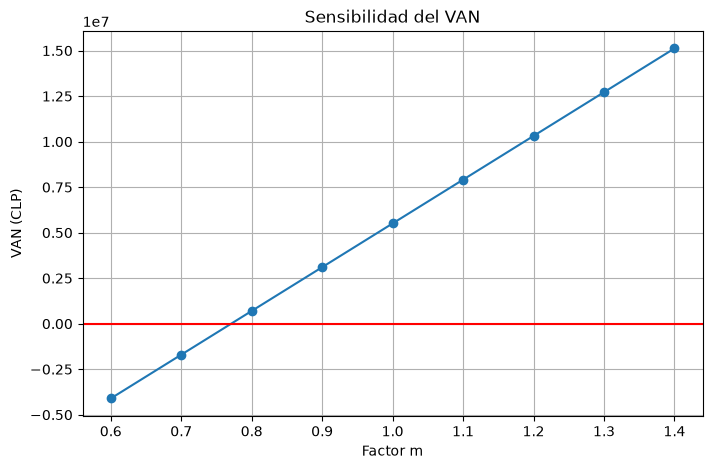

m critico = 0.77
VAN = -19649.93


In [39]:
import numpy as np
import numpy_financial as npf
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FlujoA= [-18522000,5000000,6500000,7500000,11000000]
r= (0.15*29 + 4)/100

mValores = [0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4]
VanSensibilidad = []


for m in mValores:

    Valores = [
        -18522000,
        5000000 * m,
        6500000 * m,
        7500000 * m,
        11000000 * m
    ]

    VAN = npf.npv(r, Valores)

    if abs(VAN) < 50000:
        print("m critico =", m)
        print("VAN =", VAN)
        break

for m in mValores:
    
    Valores = [-18522000 , 5000000 * m , 6500000 * m , 7500000 * m , 11000000 * m ]
    
    VAN = npf.npv(r, Valores)

    VanSensibilidad.append(VAN)

print("~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~")
print("Resumen:")

plt.figure(figsize=(8,5))

plt.plot(mValores,VanSensibilidad,marker="o")

plt.axhline(0,color="red")

plt.xlabel("Factor m")

plt.ylabel("VAN (CLP)")

plt.title("Sensibilidad del VAN")

plt.grid()

plt.show()


import numpy as np

for m in np.arange(0.60, 1.41, 0.01):

    Valores = [
        -18522000,
        5000000 * m,
        6500000 * m,
        7500000 * m,
        11000000 * m
    ]

    VAN = npf.npv(r, Valores)

    if abs(VAN) < 50000:
        print("m critico =", round(m, 2))
        print("VAN =", round(VAN, 2))
        break

explicar todo


monte carlo


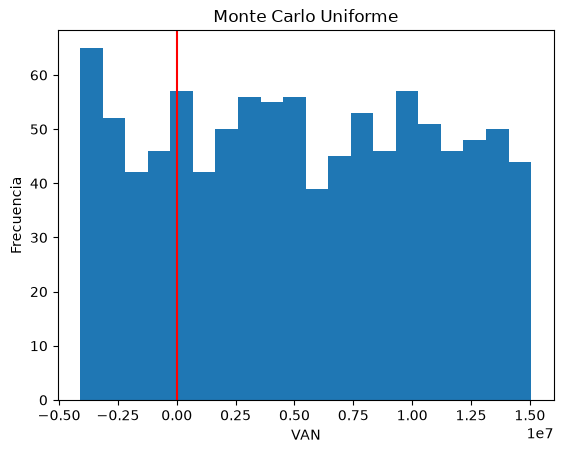

UNIFORME
Positivos: 778
Negativos: 222
% Positivos: 77.8
VAN Promedio: 5296601.279641146
Desv.Est: 5553424.767744258


In [40]:
rng = np.random.default_rng(2025730294)

m_uniforme = rng.uniform(0.60,1.40,1000)

VanUniforme = []

for m in m_uniforme:
    
    Valores = [
            -18522000,
            5000000 * m,
            6500000 * m,
            7500000 * m,
            11000000 * m
        ]
            
    VAN = npf.npv(r, Valores)

    VanUniforme.append(VAN)
    
plt.hist(VanUniforme,bins=20)

plt.axvline(0,color='red')

plt.title("Monte Carlo Uniforme")

plt.xlabel("VAN")

plt.ylabel("Frecuencia")

plt.show()

PositivosU = np.sum(np.array(VanUniforme) > 0)
NegativosU = np.sum(np.array(VanUniforme) < 0)

print("UNIFORME")
print("Positivos:",PositivosU)
print("Negativos:",NegativosU)
print("% Positivos:",PositivosU/1000*100)
print("VAN Promedio:",np.mean(VanUniforme))
print("Desv.Est:",np.std(VanUniforme))

kook

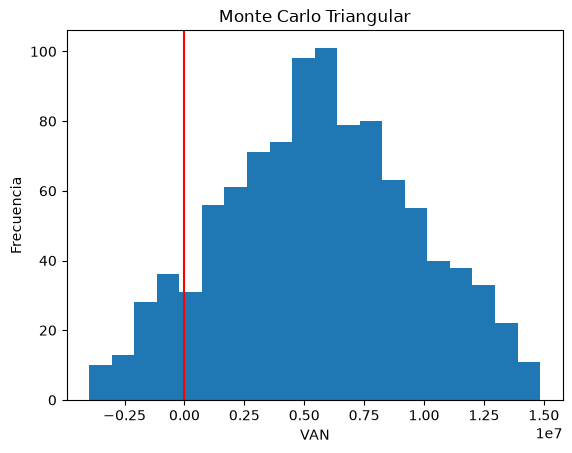

TRIANGULAR
Positivos: 906
Negativos: 94
% Positivos: 90.60000000000001
VAN Promedio: 5625148.6080550505
Desv.Est: 3992503.5670050946


In [41]:
m_triangular = rng.triangular(0.60,1.00,1.40,1000)

VanTriangular = []

for m in m_triangular:

    Valores = [ -18522000,
                 5000000 * m,
                 6500000 * m,
                 7500000 * m,
                 11000000 * m ]
            
    VAN = npf.npv(r, Valores)

    VanTriangular.append(VAN)

plt.hist(VanTriangular,bins=20)

plt.axvline(0,color='red')

plt.title("Monte Carlo Triangular")

plt.xlabel("VAN")

plt.ylabel("Frecuencia")

plt.show()

PositivosU = np.sum(np.array(VanUniforme) > 0)
NegativosU = np.sum(np.array(VanUniforme) < 0)

PositivosT = np.sum(np.array(VanTriangular) > 0)
NegativosT = np.sum(np.array(VanTriangular) < 0)

print("TRIANGULAR")
print("Positivos:",PositivosT)
print("Negativos:",NegativosT)
print("% Positivos:",PositivosT/1000*100)
print("VAN Promedio:",np.mean(VanTriangular))
print("Desv.Est:",np.std(VanTriangular))

jojojoj


In [42]:
#Uniforme

rng = np.random.default_rng(2025730294)
m_uniforme = rng.uniform(0.60,1.40,1000)
VanUniforme = []
for m in m_uniforme:
    
    Valores = [
            -18522000,
            5000000 * m,
            6500000 * m,
            7500000 * m,
            11000000 * m
        ]
            
    VAN = npf.npv(r, Valores)

    VanUniforme.append(VAN)
PositivosU = np.sum(np.array(VanUniforme) > 0)
NegativosU = np.sum(np.array(VanUniforme) < 0)


#triangular

m_triangular = rng.triangular(0.60,1.00,1.40,1000)
VanTriangular = []
for m in m_triangular:

    Valores = [ -18522000,
                 5000000 * m,
                 6500000 * m,
                 7500000 * m,
                 11000000 * m ]
            
    VAN = npf.npv(r, Valores)

    VanTriangular.append(VAN)

PositivosU = np.sum(np.array(VanUniforme) > 0)
NegativosU = np.sum(np.array(VanUniforme) < 0)

PositivosT = np.sum(np.array(VanTriangular) > 0)
NegativosT = np.sum(np.array(VanTriangular) < 0)

# tabla comparativa

TablaResultadosHistogramas = pd.DataFrame({
    "Histogramas":["Uniforme","Triangular"],
    "Positivos":[PositivosU,PositivosT],
    "Negativos:": [NegativosU,NegativosT],
    "% Positivos:":[PositivosU/1000*100,PositivosT/1000*100],
    "Inversión Inicial":[round(np.mean(VanUniforme),2), round(np.mean(VanTriangular),2)],
    "Desv.Est:":[round(np.std(VanUniforme),2) , round(np.std(VanTriangular),2)]
})

TablaResultadosHistogramas= TablaResultadosHistogramas.set_index("Histogramas")
display(TablaResultadosHistogramas)

,Positivos,Negativos:,% Positivos:,Inversión Inicial,Desv.Est:
Histogramas,,,,,
Uniforme,778,222,77.8,5296601.28,5553424.77
Triangular,906,94,90.6,5625148.61,3992503.57


## video: 
## Repositorio: https://github.com/Paz2712/Tarea3_Ingeco_python 

# CODIGO ORIGINAL(python) UTILIZADO PARA SACAR EL VALOR NETO DE TODA LA TAREA

29 (K)  1.029 (Factor de inversión)  0.08 (Tasa de descuento)  2025730294 (rol)

-18522000.0  ||
5000000  ||
6500000  ||
7500000  ||
9000000  ||
11000000  ||
Van FC_ A:  5507026.07 Tir FC_ A:  20.0 %
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
-37044000.0  ||
7000000  ||
10000000  ||
14000000  ||
18000000  ||
22000000  ||
Van FC_ B:  4903656.48 Tir FC_ B:  13.0 %
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
-10290000.0  ||
4500000  ||
3000000  ||
5500000  ||
3000000  ||
4000000  ||
Van FC_ B:  3644850.41 Tir FC_ B:  23.0 %
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Resumen: (↓)



,Año 0,Año 1,Año 2,Año 3,Año 4
Proyecto,,,,,
A,-18522000.0,5000000,6500000,7500000,11000000
B,-37044000.0,7000000,10000000,14000000,22000000
C,-10290000.0,4500000,3000000,5500000,4000000


,VAN(CLP),TIR (%),Inversión Inicial
Proyecto,,,
A,5507026.07,20.0,-18522000.0
B,4903656.48,13.0,-37044000.0
C,3644850.41,23.0,-10290000.0


m = 0.6
VAN = -4104584.36
----------------
m = 0.7
VAN = -1701681.75
----------------
m = 0.8
VAN = 701220.85
----------------
m = 0.9
VAN = 3104123.46
----------------
m = 1.0
VAN = 5507026.07
----------------
m = 1.1
VAN = 7909928.67
----------------
m = 1.2
VAN = 10312831.28
----------------
m = 1.3
VAN = 12715733.89
----------------
m = 1.4
VAN = 15118636.49
----------------
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Resumen:


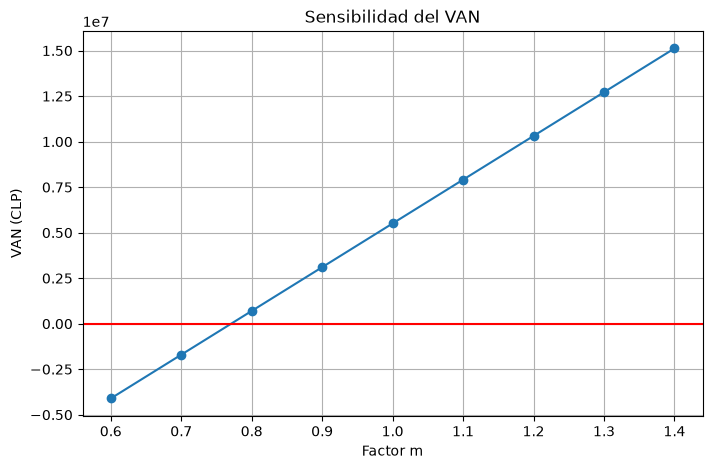

m critico = 0.7700000000000001
VAN = -19649.929190990515
~~~~~~~~~~~~~~~~~~~~~+


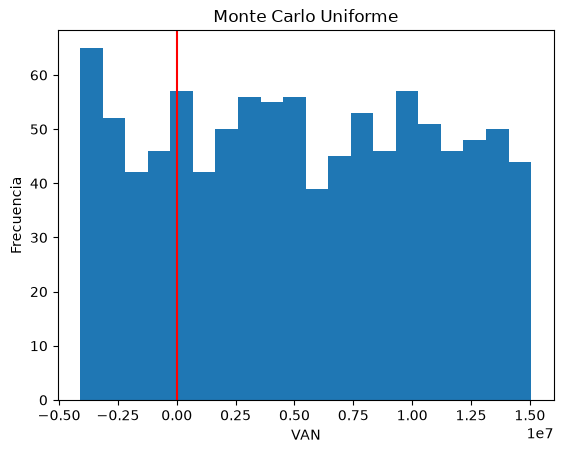

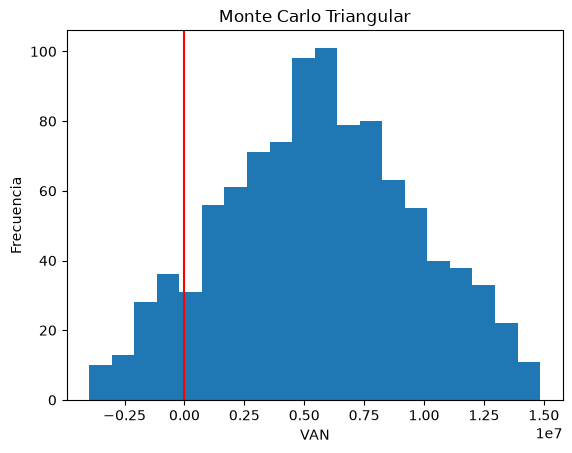

UNIFORME
Positivos: 778
Negativos: 222
% Positivos: 77.8
VAN Promedio: 5296601.279641146
Desv.Est: 5553424.767744258

TRIANGULAR
Positivos: 906
Negativos: 94
% Positivos: 90.60000000000001
VAN Promedio: 5625148.6080550505
Desv.Est: 3992503.5670050946


,Positivos,Negativos:,% Positivos:,Inversión Inicial,Desv.Est:
Histogramas,,,,,
Uniforme,778,222,77.8,5296601.28,5553424.77
Triangular,906,94,90.6,5625148.61,3992503.57


In [43]:
# el %% sirve para activar el kernel de jupiter en vscode ignoralo si ocuparas google colab
# %%

# en el caso de utilizar google colab
# quite el hashtag[#] para que corra el sigiente comando(↓)
# !pip install numpy_financial

import numpy as np
import numpy_financial as npf
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

#Tarea3_2025730294_García
#sea mi rol 202573029-4 ultimos 2 digitos componen la variable k = 94

def Factor_invercion(K):
    F = 1 + K/1000
    return(F)

#tasa de descuento real efectiva anual 
def TdescuentoRFA(K):
    R = 0.15 * K
    R= R+4
    R= R/100
    return(R)

def Sacar_FlujoCaja(**Base):
    FC = 0
    for Capital in Base:
        FC= Base[Capital]/((1+r)**i)
        print(FC)
        print(" || ")
    print("\n")
    return(FC)
    
#inicio real de act de tarea
k= 29
semilla= 2025730294
f= Factor_invercion(k)
r= TdescuentoRFA(k)

print(k, "(K) ", f, "(Factor de inversión) ", round(r,2), "(Tasa de descuento) ", semilla, "(rol)\n")
#calculos de flujo de caja
FlujoDeCaja_A = {
    'inversion_inicial (Año 0)': -18000000 * f,
        'Año 1':  5000000,
        'Año 2': 6500000,
        'Año 3': 7500000,
        'Año 4': 9000000,
        'Recuperacion(Año 4)': 2000000
}

FC = 0
i= 0
FlujoA= [0,0,0,0,0]
for Capital in FlujoDeCaja_A:
    
    FC= FlujoDeCaja_A[Capital] #/((1+r)**i)
    if i == 5:
        FlujoA[4]+= FC
        i= i -1
        print(FlujoA[i], " ||")
        
    else:
        FlujoA[i]= FC
        print(FlujoA[i], " ||")
        i+= 1
    
    
    

VanA= round(npf.npv(r,FlujoA),2)
TirA= round(npf.irr(FlujoA),2)
print("Van FC_ A: ",VanA, "Tir FC_ A: ", TirA*100 , "%")
print("~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~")

FlujoDeCaja_B = {
    'inversion_inicial (Año 0)': -36000000 * f,
            'Año 1':  7000000,
            'Año 2': 10000000,
            'Año 3': 14000000,
            'Año 4': 18000000,
            'Recuperacion(Año 4)': 4000000
}

FC= 0
i= 0
FlujoB= [0,0,0,0,0]
for Capital in FlujoDeCaja_B:
    
    FC= FlujoDeCaja_B[Capital] #/((1+r)**i)
    if i == 5:
        FlujoB[4]+= FC
        i= i -1
        print(FlujoB[i], " ||")
    else:
        FlujoB[i]= FC
        print(FlujoB[i], " ||")
        i+= 1
    
    
   
VanB= round(npf.npv(r,FlujoB),2)
TirB= round(npf.irr(FlujoB),2)
print("Van FC_ B: ",VanB, "Tir FC_ B: ", TirB*100, "%")
print("~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~")

FlujoDeCaja_C = {
    'inversion_inicial (Año 0)': -10000000 * f,
        'Año 1':  4500000,
        'Año 2': 3000000,
        'Año 3': 5500000,
        'Año 4': 3000000,
        'Recuperacion(Año 4)': 1000000
}

FC= 0
i= 0
FlujoC= [0,0,0,0,0]
for Capital in FlujoDeCaja_C:
    
    FC= FlujoDeCaja_C[Capital] #/((1+r)**i)
    if i == 5:
            FlujoC[4]+= FC
            i= i -1
            print(FlujoC[i], " ||")
    else:
        FlujoC[i]= FC
        print(FlujoC[i], " ||")
        i+= 1
    
    

VanC= round(npf.npv(r,FlujoC),2)
TirC= round(npf.irr(FlujoC),2)
print("Van FC_ B: ",VanC, "Tir FC_ B: ", TirC*100,"%")
print("~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~")

print("Resumen: (↓)\n")

TablaFlujos = pd.DataFrame({
    "Proyecto": ["A", "B", "C"],
    "Año 0": [FlujoA[0], FlujoB[0], FlujoC[0]],
    "Año 1": [FlujoA[1], FlujoB[1], FlujoC[1]],
    "Año 2": [FlujoA[2], FlujoB[2], FlujoC[2]],
    "Año 3": [FlujoA[3], FlujoB[3], FlujoC[3]],
    "Año 4": [FlujoA[4], FlujoB[4], FlujoC[4]]
})

TablaFlujos = TablaFlujos.set_index("Proyecto")

display(TablaFlujos)
    
TablaResultados = pd.DataFrame({
    "Proyecto":["A","B","C"],
    "VAN(CLP)":[VanA,VanB,VanC],
    "TIR (%)":[TirA*100,TirB*100,TirC*100],
    "Inversión Inicial":[FlujoA[0],FlujoB[0],FlujoC[0]]
})

TablaResultados= TablaResultados.set_index("Proyecto")

display(TablaResultados)

"""
Parte 2; explicación
"""


'''
Parte 3
'''

#sea el proyecto escojido el A
mValores = [0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4]
VanSensibilidad = []

i=0
Valor = [0,0,0,0,0]

while (i < 5):
    Valor[i] = FlujoA[i]
    i+= 1

Valores = [0,0,0,0,0]

for m in mValores:
    
    Valores[0] = Valor[0]
    Valores[1] = Valor[1] * m
    Valores[2] = Valor[2] * m
    Valores[3] = Valor[3] * m
    Valores[4] = Valor[4] * m     
    
    VAN = npf.npv(r, Valores)

    VanSensibilidad.append(VAN)

    print("m =",m)
    print("VAN =",round(VAN,2))
    print("----------------")

print("~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~")
print("Resumen:")

plt.figure(figsize=(8,5))

plt.plot(mValores,VanSensibilidad,marker="o")

plt.axhline(0,color="red")

plt.xlabel("Factor m")

plt.ylabel("VAN (CLP)")

plt.title("Sensibilidad del VAN")

plt.grid()

plt.show()

"""
explicaion graf
"""

for m in np.arange(0.6,1.41,0.01):
    
    Valores[0] = Valor[0]
    Valores[1] = Valor[1] * m
    Valores[2] = Valor[2] * m
    Valores[3] = Valor[3] * m
    Valores[4] = Valor[4] * m     
        
    VAN = npf.npv(r, Valores)
    
    VanSensibilidad.append(VAN)

    

    if abs(VAN) < 50000:
        print("m critico =",m)
        print("VAN =",VAN)
        break
    
print("~~~~~~~~~~~~~~~~~~~~~+")

rng = np.random.default_rng(2025730294)

m_uniforme = rng.uniform(0.60,1.40,1000)

VanUniforme = []

for m in m_uniforme:
    
    Valores[0] = Valor[0]
    Valores[1] = Valor[1] * m
    Valores[2] = Valor[2] * m
    Valores[3] = Valor[3] * m
    Valores[4] = Valor[4] * m     
            
    VAN = npf.npv(r, Valores)

    VanUniforme.append(VAN)

m_triangular = rng.triangular(0.60,1.00,1.40,1000)

VanTriangular = []

for m in m_triangular:

    Valores[0] = Valor[0]
    Valores[1] = Valor[1] * m
    Valores[2] = Valor[2] * m
    Valores[3] = Valor[3] * m
    Valores[4] = Valor[4] * m     
            
    VAN = npf.npv(r, Valores)

    VanTriangular.append(VAN)

plt.hist(VanUniforme,bins=20)

plt.axvline(0,color='red')

plt.title("Monte Carlo Uniforme")

plt.xlabel("VAN")

plt.ylabel("Frecuencia")

plt.show()

plt.hist(VanTriangular,bins=20)

plt.axvline(0,color='red')

plt.title("Monte Carlo Triangular")

plt.xlabel("VAN")

plt.ylabel("Frecuencia")

plt.show()

PositivosU = np.sum(np.array(VanUniforme) > 0)
NegativosU = np.sum(np.array(VanUniforme) < 0)

PositivosT = np.sum(np.array(VanTriangular) > 0)
NegativosT = np.sum(np.array(VanTriangular) < 0)

print("UNIFORME")
print("Positivos:",PositivosU)
print("Negativos:",NegativosU)
print("% Positivos:",PositivosU/1000*100)
print("VAN Promedio:",np.mean(VanUniforme))
print("Desv.Est:",np.std(VanUniforme))

print()

print("TRIANGULAR")
print("Positivos:",PositivosT)
print("Negativos:",NegativosT)
print("% Positivos:",PositivosT/1000*100)
print("VAN Promedio:",np.mean(VanTriangular))
print("Desv.Est:",np.std(VanTriangular))

# tabla comparativa

TablaResultadosHistogramas = pd.DataFrame({
    "Histogramas":["Uniforme","Triangular"],
    "Positivos":[PositivosU,PositivosT],
    "Negativos:": [NegativosU,NegativosT],
    "% Positivos:":[PositivosU/1000*100,PositivosT/1000*100],
    "Inversión Inicial":[round(np.mean(VanUniforme),2), round(np.mean(VanTriangular),2)],
    "Desv.Est:":[round(np.std(VanUniforme),2) , round(np.std(VanTriangular),2)]
})

TablaResultadosHistogramas= TablaResultadosHistogramas.set_index("Histogramas")
display(TablaResultadosHistogramas)

# %%
